In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
# === User configuration ===
csv_path = "exp_prelr1e-4_lr1e-5_step3_gamma0.5_epochs5_rounds100_cls7_ch6_win1024_stride256_bs32_wd0_013"
# list_of_experiments = ['A', 'B', 'C']
list_of_experiments = ['A']
file_type = "csv"

# Label mapping
mapping = {
    'lying': 0,
    'sitting': 1,
    'standing': 2,
    'ascending stairs': 3,
    'descending stairs': 4,
    'walking': 5,
    'running': 6
}

plt.style.use('seaborn-v0_8')

In [3]:
# === Plotting function ===
def plot_metrics(train_pivot, val_pivot, train_metric, test_metric, train_label, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(train_pivot.index, train_pivot[train_metric], label=train_label, marker='o')
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


In [4]:
# === Plotting function ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [5]:
dfs = {}

for xp in list_of_experiments:
    df = pd.read_csv(f"{csv_path}{xp}.{file_type}")
    df['validation'] = df['validation'].astype(bool)
    
    df_train = df[df['validation'] == False]
    df_val = df[df['validation'] == True]

    dfs[xp] = {"users": {}}  # store per-user pivots here
    
    users = df['user'].unique()
    users.sort()  # sorts the array in place
    for user in users:
        cent_df_train = df_train[df_train['user'] == user]
        cent_df_val = df_val[df_val['user'] == user]
        
        cent_train_pivot = cent_df_train.pivot(index='epoch', columns='metric', values='values').astype(float)
        cent_val_pivot = cent_df_val.pivot(index='epoch', columns='metric', values='values')
        
        excluded_column = 'metrics.TEST_CONF'
        cent_val_pivot.loc[:, cent_val_pivot.columns != excluded_column] = (
            cent_val_pivot.loc[:, cent_val_pivot.columns != excluded_column].astype(float)
        )
        
        dfs[xp]["users"][user] = {
            "df_train": cent_df_train,
            "df_val": cent_df_val,
            "train_pivot": cent_train_pivot,
            "val_pivot": cent_val_pivot
        }

print("Data loaded and prepared for experiments:", list(dfs.keys()))
colors = plt.get_cmap('tab10', len(users))  # modern API

Data loaded and prepared for experiments: ['A']



=== Experiment A ===


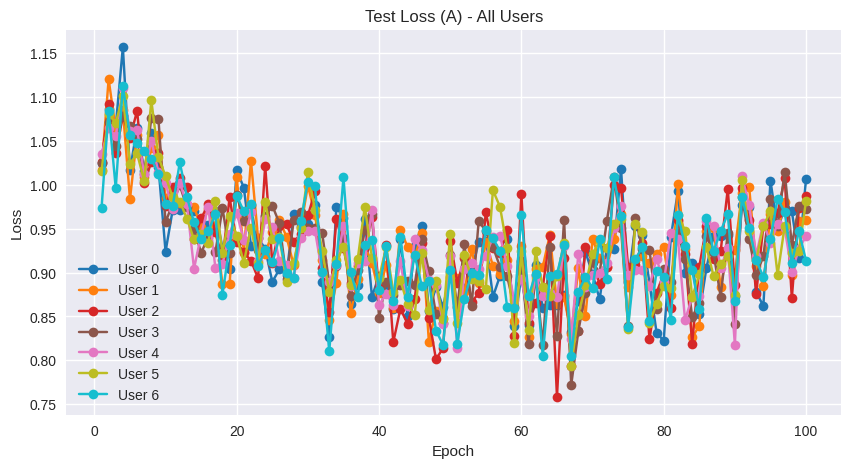

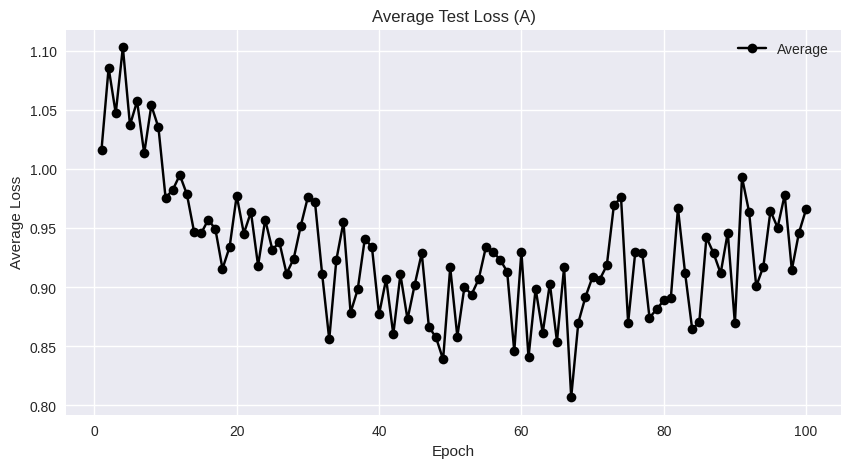

In [6]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    plt.figure(figsize=(10, 5))
    
    all_losses = []  # store each user's LOSS series
    
    for i, user in enumerate(users):
        val_pivot = dfs[xp]["users"][user]['val_pivot']
        plt.plot(
            val_pivot.index,
            val_pivot['metrics.LOSS'],
            label=f'User {user}',
            marker='o',
            color=colors(i)
        )
        # collect loss for averaging
        all_losses.append(val_pivot['metrics.LOSS'])
    
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Test Loss ({xp}) - All Users')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---- Plot average loss ----
    if all_losses:
        df_all = pd.concat(all_losses, axis=1)  # combine user loss series
        avg_loss = df_all.mean(axis=1)          # compute epoch-wise average

        plt.figure(figsize=(10, 5))
        plt.plot(avg_loss.index, avg_loss, marker='o', color='black', label='Average')
        plt.xlabel('Epoch')
        plt.ylabel('Average Loss')
        plt.title(f'Average Test Loss ({xp})')
        plt.legend()
        plt.grid(True)
        plt.show()



=== Experiment A ===


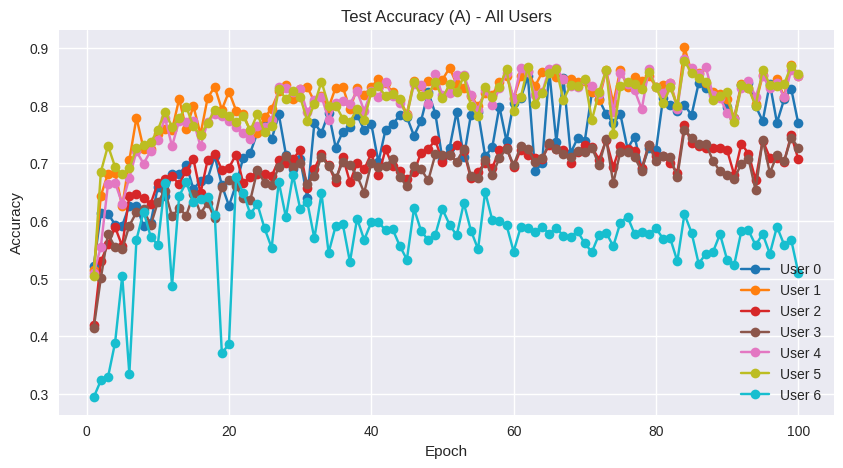

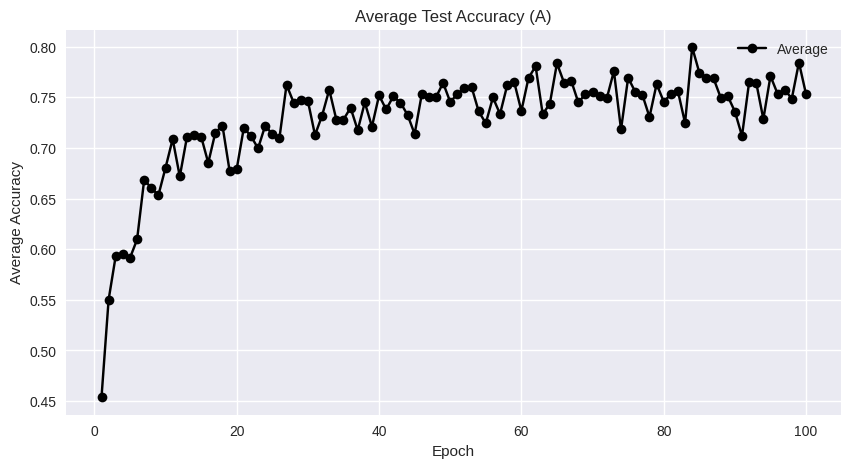

In [7]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    plt.figure(figsize=(10, 5))
    
    all_accuracies = []  # store each user's TEST_ACC series
    
    for i, user in enumerate(users):
        val_pivot = dfs[xp]["users"][user]['val_pivot']
        plt.plot(
            val_pivot.index,
            val_pivot['metrics.TEST_ACC'],
            label=f'User {user}',
            marker='o',
            color=colors(i)
        )
        # collect accuracy for averaging
        all_accuracies.append(val_pivot['metrics.TEST_ACC'])
    
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'Test Accuracy ({xp}) - All Users')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---- Plot average accuracy ----
    if all_accuracies:
        df_all = pd.concat(all_accuracies, axis=1)  # combine all user accuracy series
        avg_accuracy = df_all.mean(axis=1)          # compute epoch-wise average

        plt.figure(figsize=(10, 5))
        plt.plot(avg_accuracy.index, avg_accuracy, marker='o', color='black', label='Average')
        plt.xlabel('Epoch')
        plt.ylabel('Average Accuracy')
        plt.title(f'Average Test Accuracy ({xp})')
        plt.legend()
        plt.grid(True)
        plt.show()



=== Experiment A ===


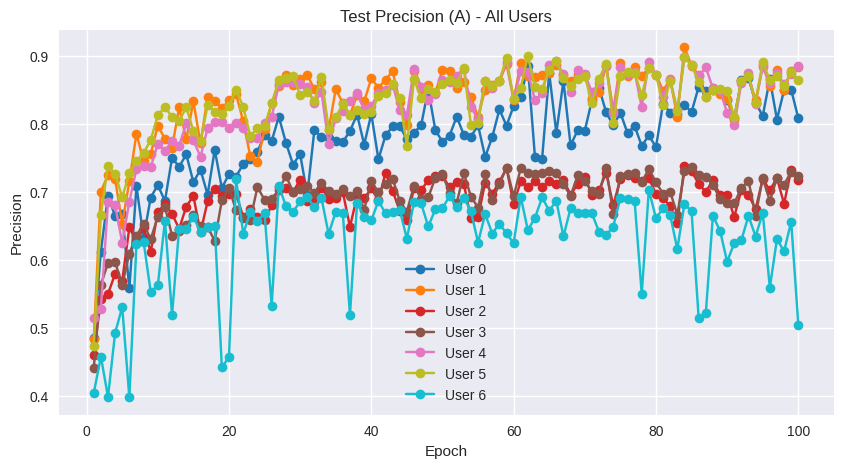

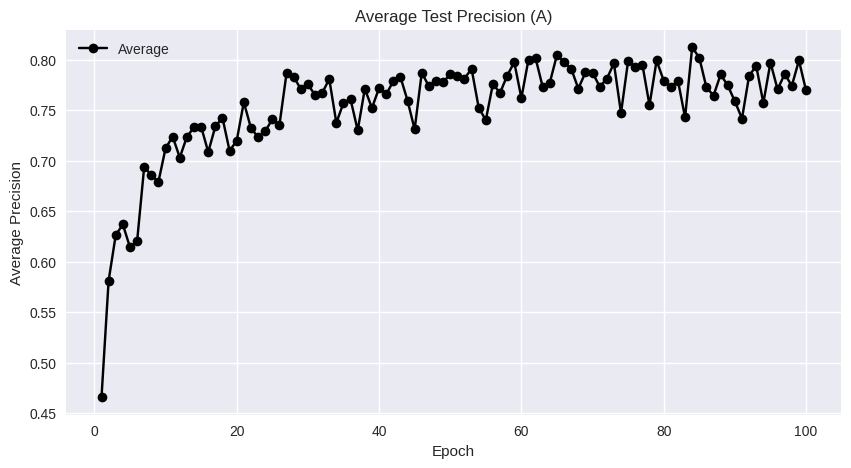

In [8]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    plt.figure(figsize=(10, 5))
    
    all_precisions = []  # store each user's TEST_PREC series
    
    for i, user in enumerate(users):
        val_pivot = dfs[xp]["users"][user]['val_pivot']
        plt.plot(
            val_pivot.index,
            val_pivot['metrics.TEST_PREC'],
            label=f'User {user}',
            marker='o',
            color=colors(i)
        )
        # collect precision for averaging
        all_precisions.append(val_pivot['metrics.TEST_PREC'])
    
    plt.xlabel('Epoch')
    plt.ylabel('Precision')
    plt.title(f'Test Precision ({xp}) - All Users')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---- Plot average precision ----
    if all_precisions:  # check we have data
        # Combine all user series into one DataFrame (align by index/epoch)
        df_all = pd.concat(all_precisions, axis=1)
        avg_precision = df_all.mean(axis=1)

        plt.figure(figsize=(10, 5))
        plt.plot(avg_precision.index, avg_precision, marker='o', color='black', label='Average')
        plt.xlabel('Epoch')
        plt.ylabel('Average Precision')
        plt.title(f'Average Test Precision ({xp})')
        plt.legend()
        plt.grid(True)
        plt.show()



=== Experiment A ===


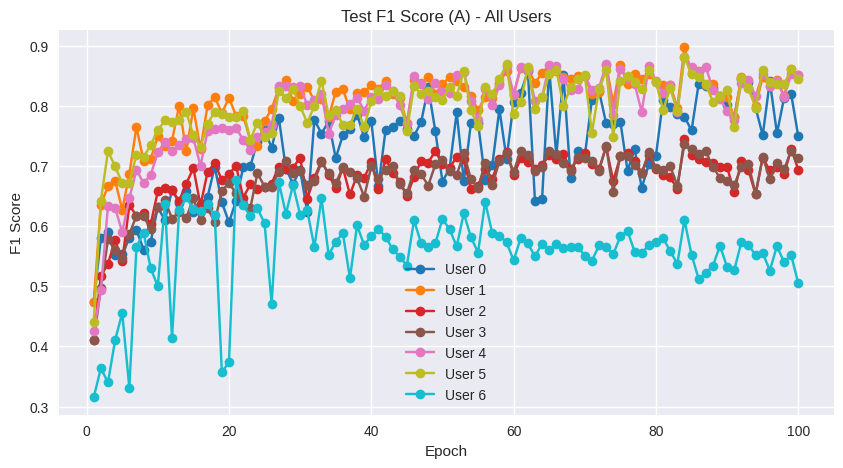

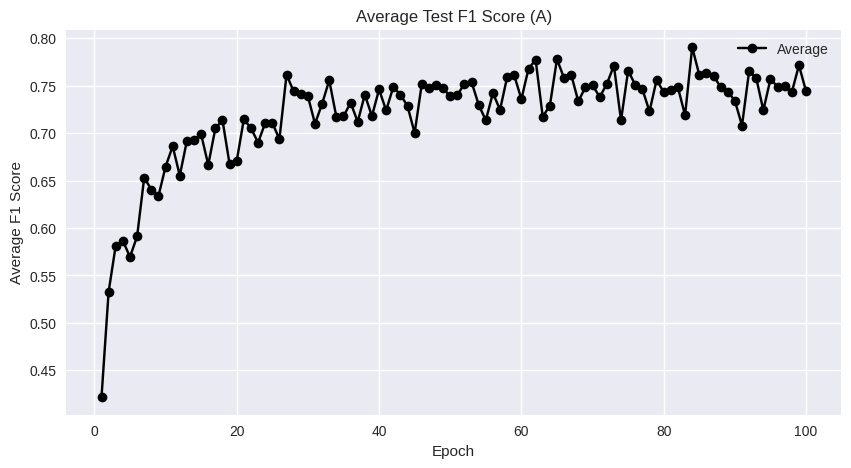

In [9]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    plt.figure(figsize=(10, 5))

    users = list(dfs[xp]["users"].keys())
    all_f1 = []  # store each user's TEST_F1 series
    
    for i, user in enumerate(users):
        val_pivot = dfs[xp]["users"][user]['val_pivot']
        plt.plot(
            val_pivot.index,
            val_pivot['metrics.TEST_F1'],
            label=f'User {user}',
            marker='o',
            color=colors(i)  # assign a unique color per user
        )
        # collect F1 for averaging
        all_f1.append(val_pivot['metrics.TEST_F1'])
    
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.title(f'Test F1 Score ({xp}) - All Users')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---- Plot average F1 ----
    if all_f1:
        df_all = pd.concat(all_f1, axis=1)  # combine user F1 series
        avg_f1 = df_all.mean(axis=1)        # compute epoch-wise average

        plt.figure(figsize=(10, 5))
        plt.plot(avg_f1.index, avg_f1, marker='o', color='black', label='Average')
        plt.xlabel('Epoch')
        plt.ylabel('Average F1 Score')
        plt.title(f'Average Test F1 Score ({xp})')
        plt.legend()
        plt.grid(True)
        plt.show()


In [10]:
# Collect metrics for averaging
acc_list = []
prec_list = []
f1_list = []

for xp in dfs:
    acc_users = []
    prec_users = []
    f1_users = []
    
    for user, user_data in dfs[xp]["users"].items():
        val_pivot = user_data['val_pivot']
        max_index = val_pivot['metrics.TEST_ACC'].idxmax()
        
        acc_users.append(val_pivot['metrics.TEST_ACC'][max_index])
        prec_users.append(val_pivot['metrics.TEST_PREC'][max_index])
        f1_users.append(val_pivot['metrics.TEST_F1'][max_index])
    
    # Average across users for this experiment
    acc_avg = sum(acc_users) / len(acc_users)
    prec_avg = sum(prec_users) / len(prec_users)
    f1_avg = sum(f1_users) / len(f1_users)
    
    acc_list.append(acc_avg)
    prec_list.append(prec_avg)
    f1_list.append(f1_avg)
    
    print(f"\n=== Best Epoch for Experiment {xp} (averaged over users) ===")
    print(f"Balanced Accuracy: {acc_avg:.4f}")
    print(f"Precision: {prec_avg:.4f}")
    print(f"F1 Score: {f1_avg:.4f}")

# Print averages across experiments
print("\n=== Average Across Experiments ===")
print(f"Average Balanced Accuracy: {sum(acc_list) / len(acc_list):.4f}")
print(f"Average Precision: {sum(prec_list) / len(prec_list):.4f}")
print(f"Average F1 Score: {sum(f1_list) / len(f1_list):.4f}")



=== Best Epoch for Experiment A (averaged over users) ===
Balanced Accuracy: 0.8176
Precision: 0.8173
F1 Score: 0.8101

=== Average Across Experiments ===
Average Balanced Accuracy: 0.8176
Average Precision: 0.8173
Average F1 Score: 0.8101


In [11]:
import re

output_file = f"{csv_path}.txt"

with open(output_file, "w") as f:
    f.write("=== Experiment Parameters ===\n")
    
    # Split csv_path into parts and write them
    parts = csv_path.split("_")
    for part in parts:
        match = re.match(r"([a-zA-Z]+)([0-9\.\-eE]+)", part)
        if match:
            name, value = match.groups()
            f.write(f"{name} {value}\n")
        else:
            f.write(f"{part}\n")
    
    f.write("\n=== Best Epoch Results per Experiment (averaged across users) ===\n")
    
    exp_acc_list = []
    exp_prec_list = []
    exp_f1_list = []
    
    for xp in dfs:
        acc_users = []
        prec_users = []
        f1_users = []
        
        for user, user_data in dfs[xp]["users"].items():
            val_pivot = user_data['val_pivot']
            max_index = val_pivot['metrics.TEST_ACC'].idxmax()
            
            acc_users.append(val_pivot['metrics.TEST_ACC'][max_index])
            prec_users.append(val_pivot['metrics.TEST_PREC'][max_index])
            f1_users.append(val_pivot['metrics.TEST_F1'][max_index])
            
            # Write per-user results
            f.write(f"\nExperiment {xp} - User {user}:\n")
            f.write(f"Balanced Accuracy: {val_pivot['metrics.TEST_ACC'][max_index]}\n")
            f.write(f"Precision: {val_pivot['metrics.TEST_PREC'][max_index]}\n")
            f.write(f"F1 Score: {val_pivot['metrics.TEST_F1'][max_index]}\n")
        
        # Average across users for this experiment
        acc_avg = sum(acc_users) / len(acc_users)
        prec_avg = sum(prec_users) / len(prec_users)
        f1_avg = sum(f1_users) / len(f1_users)
        
        exp_acc_list.append(acc_avg)
        exp_prec_list.append(prec_avg)
        exp_f1_list.append(f1_avg)
        
        f.write(f"\nExperiment {xp} (Averaged across users):\n")
        f.write(f"Balanced Accuracy: {acc_avg:.4f}\n")
        f.write(f"Precision: {prec_avg:.4f}\n")
        f.write(f"F1 Score: {f1_avg:.4f}\n")
    
    # Average across experiments
    f.write("\n=== Average Across Experiments (user-averaged) ===\n")
    f.write(f"Average Balanced Accuracy: {sum(exp_acc_list) / len(exp_acc_list):.4f}\n")
    f.write(f"Average Precision: {sum(exp_prec_list) / len(exp_prec_list):.4f}\n")
    f.write(f"Average F1 Score: {sum(exp_f1_list) / len(exp_f1_list):.4f}\n")

print(f"Results saved to {output_file}")


Results saved to exp_prelr1e-4_lr1e-5_step3_gamma0.5_epochs5_rounds100_cls7_ch6_win1024_stride256_bs32_wd0_013.txt
